# Predicting Injury Severity on Amusement Park Rides

#### Ann Jojo, Gerardo Martinez

In this notebook, we use data from amusement park and carnival ride incidents to predict injury severity. The dataset includes accidents reported in the United States and has information such as injury descriptions, ride types, and contributing factors related to each incident. The dataset was created from the Saferparks database specifically the 2017 Accident Data Set:
https://ridesdatabase.org/wp-content/uploads/2022/04/Saferparks-dataset-2017-v4.csv


The goal is to predict injury severity on a scale of one to five using information that is available before an accident occurs. This is a classification problem and our goal is to figure out whether certain types of rides or environments are more likely to create severe injuries. This could be used to improve safety at amusement parks and help create better park designs to protect riders and people nearby ride structures.

In [ ]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.model_selection import train_test_split, learning_curve, GridSearchCV
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict
from IPython.display import display, HTML
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree

Plotting settings

In [ ]:
sns.set_theme(context='notebook', style='whitegrid')

# set default plot size
plt.rcParams['figure.figsize'] = 6,4

In [ ]:
# make the notebook width equal to 90% of the browser window width
display(HTML("<style>.container { width:90% !important; }</style>"))

## Read the data

In [ ]:
input_file = "https://raw.githubusercontent.com/Gerardo2106/mLproject/main/Saferparks-dataset-2017-v4.csv"
df = pd.read_csv(input_file, encoding='latin1')

## Data exploration

We start off by exploring the dataset to understand the data value distributions and to also identify patterns that could help improve prediction.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8351 entries, 0 to 8350
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   acc_id                8351 non-null   int64  
 1   acc_date              8351 non-null   object 
 2   acc_state             8351 non-null   object 
 3   acc_city              8233 non-null   object 
 4   fix_port              8351 non-null   object 
 5   source                8351 non-null   object 
 6   bus_type              8351 non-null   object 
 7   industry_sector       8351 non-null   object 
 8   device_category       8351 non-null   object 
 9   device_type           8351 non-null   object 
 10  tradename_or_generic  8351 non-null   object 
 11  manufacturer          5041 non-null   object 
 12  num_injured           8349 non-null   float64
 13  age_youngest          7667 non-null   float64
 14  gender                7623 non-null   object 
 15  acc_desc             

It will be useful to take a look at the data values for each of the columns to potentially identify messy data.

In [ ]:
df.head()

,acc_id,acc_date,acc_state,acc_city,fix_port,source,bus_type,industry_sector,device_category,device_type,...,age_youngest,gender,acc_desc,injury_desc,report,category,mechanical,op_error,employee,notes
0,1005813,6/12/2010,OH,Cleveland,F,Ohio Dept. of Agriculture,Sports or recreation facility,recreation,inflatable,Inflatable slide,...,NaN,NaN,Inflatable slide tipped over while 7-9 patrons...,The man who was crushed by the device died 9 d...,https://ridesdatabase.org/accident_reports/OH-...,"Device tipped over, blew away, or collapsed",NaN,1.0,NaN,http://www.cleveland.com/metro/index.ssf/2012/...
1,1004032,6/12/2010,OH,Cleveland,P,United States Consumer Product Safety Commission,Sports or recreation facility,recreation,inflatable,Inflatable slide,...,54.0,M,Two adult males were standing next to an infla...,1 - death from pulmonary embolism caused by bl...,https://ridesdatabase.org/accident_reports/CPS...,"Device tipped over, blew away, or collapsed",NaN,1.0,NaN,See also OH state record.
2,1007658,7/10/2010,CA,Anaheim,F,California Division of Occupational Safety and...,Amusement park,amusement ride,water ride,Boat ride,...,37.0,F,Patron stated she slipped and fell while stepp...,"Hip and low back pain, torn meniscus in knee",NaN,Load/Unload: scrape or stumble,NaN,NaN,NaN,NaN
3,1007098,7/10/2010,CA,Carlsbad,F,California Division of Occupational Safety and...,Water park,water park,float attraction,Lazy river,...,37.0,F,Patron claims strained back after her raft tip...,Strained back,NaN,"Fall: patron fell off inner tube, mat or board",NaN,NaN,NaN,NaN
4,1000094,7/29/2010,CO,Littleton,F,Colorado Division of Oil and Public Safety,Family entertainment center,recreation,challenge activity,Climbing wall,...,NaN,M,"Two patrons climbed to the top of the wall, co...",Patron experienced a free fall that resulted i...,https://ridesdatabase.org/accident_reports/CO-...,Fall: patron fell from device (participatory),1.0,NaN,NaN,NaN


We can see that some columns such as accident date, source, report links, operator error, and notes contain N/A which  is not useful for prediction. Therefore, it is best to drop these columums in data pre-processing to reduce the noise.

We are considering whether to keep the manufacturer column and check to see if it contains useful information or if it should be removed. If the column has too many missing values, it might harm the ML model. The goal of this is to decide whether to keep or remove this feature during pre-processing.

In [ ]:
df['manufacturer'].isna().mean()

np.float64(0.39635971739911385)

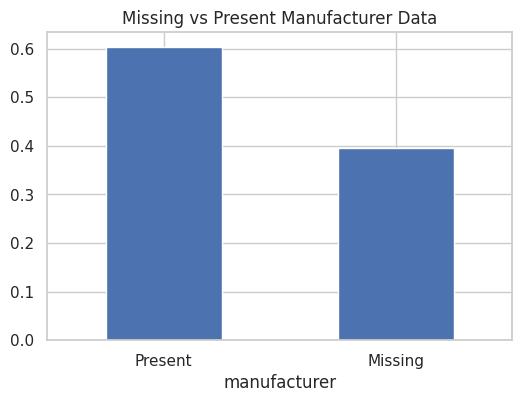

In [ ]:
df['manufacturer'].isna().value_counts(normalize=True).plot.bar()
plt.xticks([0,1], ['Present', 'Missing'], rotation=0)
plt.title('Missing vs Present Manufacturer Data');

About 40% of manufacturer column values are missing. This could reduce its usefulness for machine learning.

Let's also see who are the top manufacturers for these rides. This could be helpful to see if different manufacturers have different safety levels.

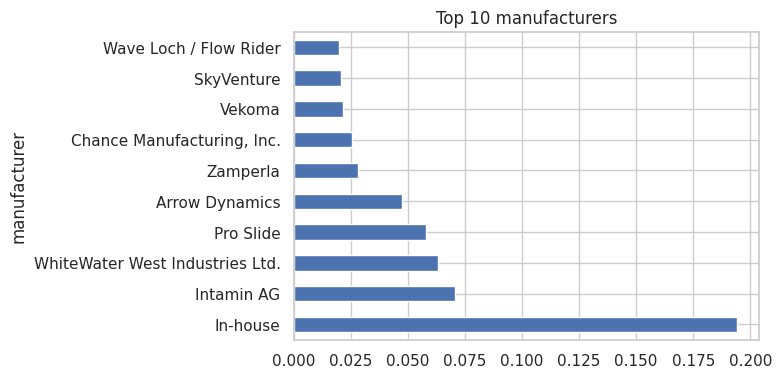

In [ ]:
df['manufacturer'].value_counts(normalize=True).head(10).plot.barh()
plt.title('Top 10 manufacturers');

The manufacturer column has a large number of unique categories. The distribution is also very imbalanced with the "In-house" one showing up significantly more times than the other manufacturers. This means that it is best to drop this column during pre-processing.

We're curious to see what are the main causes of accidents. Do different accident types lead to different severity levels? If so, this could be an important predictor.

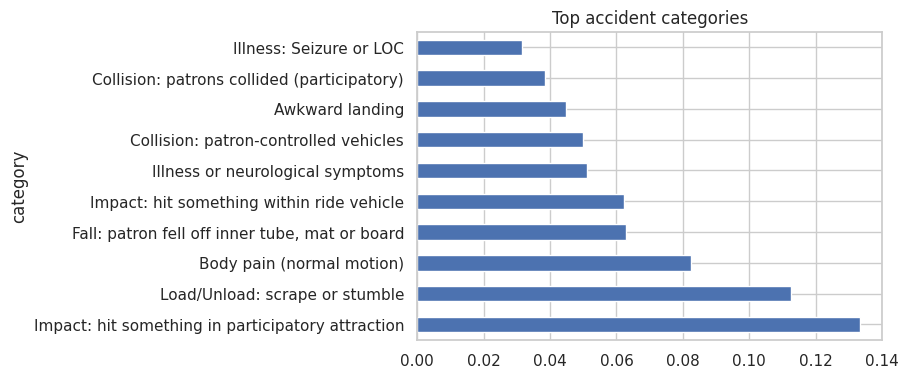

In [ ]:
df['category'].value_counts(normalize=True).head(10).plot.barh()
plt.title('Top accident categories');

We can see that a small number of categories, such as impacts and load/unload incidents make a large proportion of cases. Since this column has repeated values it may be a useful predictor for our machine learning model.

Should we keep the mechanical column? Plotting it might help us answer that.

In [ ]:
df['mechanical'].isna().mean()

np.float64(0.9552149443180458)

Approximately 95% of the values are missing here, so most accidents did not have a mechanical issue, or that information might not have been recorded. For plotting purposes, we're going to interpret missing values as no mechanical issues.

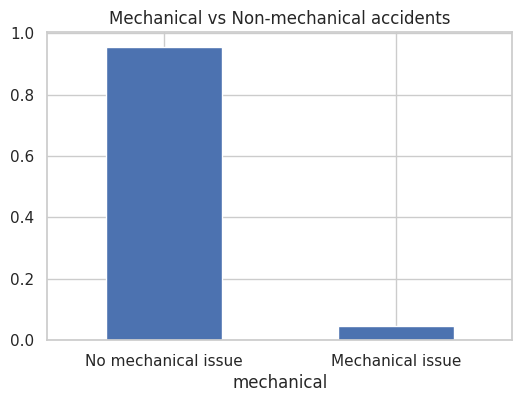

In [ ]:
df['mechanical'].fillna(0).value_counts(normalize=True).plot.bar()
plt.xticks([0,1], ['No mechanical issue', 'Mechanical issue'], rotation=0)
plt.title('Mechanical vs Non-mechanical accidents');

We can see that the majority of the accidents or not because of mechanical issues, and might be because of the riders or other factors such as the environment rather than the equipment failing. This might mean that the mechanical column might not be a good predictor for injury severity.

Let's take a look at what injuries are the most common. This can help us to group together injuries and also determine which injuries are more severe.

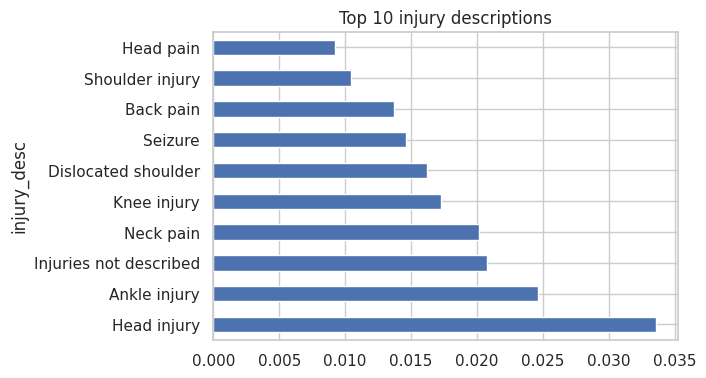

In [ ]:
df['injury_desc'].value_counts(normalize=True).head(10).plot.barh()
plt.title('Top 10 injury descriptions');

The most common injuries seem to be head injuries, ankle injuries, and neck pain. There is also a category that says “Injuries not described” which might mean that there are some cases which lack detailed information. We're also seeing repetitive categories such as head pain vs head injury.
It just might be better to group things such as:
- head injury
- upper body injury
- lower body injury

Grouping it in categories like this will also help machine learning models, especially when it comes to predicting the injury severity as it has categories to base it off of.

How many values are there for all of our predictors:

In [ ]:
df['fix_port'].value_counts()

,count
fix_port,
F,7649
P,697
U,5


In [ ]:
df['industry_sector'].value_counts()

,count
industry_sector,
amusement ride,3634
water park,2374
recreation,2337
unknown,6


In [ ]:
df['device_category'].value_counts()

,count
device_category,
water slide,1647
coaster,1184
spinning,914
trampoline,698
go-kart,620
cars & track rides,586
water ride,526
inflatable,427
challenge activity,365


In [ ]:
df['device_type'].value_counts()

,count
device_type,
Coaster - steel,863
Trampoline court,677
Go-kart,620
Tube slide,511
Aquatic play area,333
...,...
Coaster - unidentified,2
Freefall,1
gymnastics equipment,1


## Data Preprocessing

Here we're going to clean and prepare the data for machine learning. We're going to remove irrelevant columns, handle missing values, and transform variables so it could be understood by the model, such as numeric values. Each of the steps is done to make sure that the model can learn meaningful information to later find strong patterns.

In [ ]:
df.copy()

,acc_id,acc_date,acc_state,acc_city,fix_port,source,bus_type,industry_sector,device_category,device_type,...,age_youngest,gender,acc_desc,injury_desc,report,category,mechanical,op_error,employee,notes
0,1005813,6/12/2010,OH,Cleveland,F,Ohio Dept. of Agriculture,Sports or recreation facility,recreation,inflatable,Inflatable slide,...,NaN,NaN,Inflatable slide tipped over while 7-9 patrons...,The man who was crushed by the device died 9 d...,https://ridesdatabase.org/accident_reports/OH-...,"Device tipped over, blew away, or collapsed",NaN,1.0,NaN,http://www.cleveland.com/metro/index.ssf/2012/...
1,1004032,6/12/2010,OH,Cleveland,P,United States Consumer Product Safety Commission,Sports or recreation facility,recreation,inflatable,Inflatable slide,...,54.0,M,Two adult males were standing next to an infla...,1 - death from pulmonary embolism caused by bl...,https://ridesdatabase.org/accident_reports/CPS...,"Device tipped over, blew away, or collapsed",NaN,1.0,NaN,See also OH state record.
2,1007658,7/10/2010,CA,Anaheim,F,California Division of Occupational Safety and...,Amusement park,amusement ride,water ride,Boat ride,...,37.0,F,Patron stated she slipped and fell while stepp...,"Hip and low back pain, torn meniscus in knee",NaN,Load/Unload: scrape or stumble,NaN,NaN,NaN,NaN
3,1007098,7/10/2010,CA,Carlsbad,F,California Division of Occupational Safety and...,Water park,water park,float attraction,Lazy river,...,37.0,F,Patron claims strained back after her raft tip...,Strained back,NaN,"Fall: patron fell off inner tube, mat or board",NaN,NaN,NaN,NaN
4,1000094,7/29/2010,CO,Littleton,F,Colorado Division of Oil and Public Safety,Family entertainment center,recreation,challenge activity,Climbing wall,...,NaN,M,"Two patrons climbed to the top of the wall, co...",Patron experienced a free fall that resulted i...,https://ridesdatabase.org/accident_reports/CO-...,Fall: patron fell from device (participatory),1.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8346,1002532,3/31/2017,TN,Pigeon Forge,F,Tennessee Dept. of Labor and Workforce Develop...,Trampoline park,recreation,trampoline,Trampoline court,...,NaN,NaN,Patron went to catch themselves from falling a...,Arm injury,NaN,Awkward landing,NaN,NaN,NaN,NaN
8347,1004577,5/18/2017,WA,Port Townsend,P,Washington Dept. of Labor and Industries,Carnival or rental,amusement ride,spinning,Ferris/gondola wheel,...,7.0,M,"Three people (47yo female, 59yo female, 7yo ma...",The 59yo was airlifted in critical condition w...,NaN,Fall: ejection/fall from ride,NaN,NaN,NaN,http://www.kiro7.com/news/local/1-person-falls...
8348,1005814,6/7/2017,PA,Stroudsburg,F,Media Report,Go kart track,recreation,go-kart,Go-kart,...,21.0,F,"While driving one of the go-karts, and wearing...","Patron's hair and scalp were ripped off, leavi...",NaN,Entrapment or pinch-point,NaN,NaN,NaN,http://www.pahomepage.com/news/go-kart-facilit...
8349,1001736,6/30/2017,OH,Sandusky,F,Ohio Dept. of Agriculture,Amusement park,amusement ride,water ride,Flume ride,...,14.0,M,"As ride was descending down the waterfall, the...",Fractured arm,NaN,Impact: hit something within ride vehicle,NaN,NaN,NaN,NaN


We will be creating a new dataframe where all rows have the 'bus_type' of amusement park or carnival to keep data focused on only amusement park injuries.

In [ ]:
df = df[df['bus_type'].isin(['Amusement park', 'Carnival or rental'])]

Lets you confirm only the 2 categories remain.

In [ ]:
df['bus_type'].value_counts()

,count
bus_type,
Amusement park,3667
Carnival or rental,701


Like we discovered in data exploration, these columns contain unstructured text and urls, so it's best to drop them before machine learning.

In [ ]:
cols_to_drop = ['acc_date', 'source', 'report', 'op_error', 'notes', 'manufacturer']
df = df.drop(columns=cols_to_drop)

We will clean the data to remove any empty or unnnecessary injury descriptions such as "Unknown" or "Injuries not described".

In [ ]:
df = df[df['injury_desc'].notna()]

Test to confirm all empty descriptions were removed.

In [ ]:
df['injury_desc'].isna().sum()

np.int64(0)

The 'injury_desc' column contained many repeated and similar descriptions written in different ways. To make the data easier to analyze, we grouped similar descriptions into broader categories. For example, entries like “head injury” and “hit to the head” were combined into a single “Head Injury” group. The grouping logic was developed with assistance from ChatGPT

In [ ]:
def get_injury_group(desc):
    desc = str(desc).lower()

    if 'death' in desc or 'died' in desc or 'fatal' in desc:
        return 'Death'
    elif any(x in desc for x in [
        'head','concussion','brain',
        'face','facial','tooth','dental','mouth',
        'consciousness'
    ]):
        return 'Head Injury'
    elif any(x in desc for x in [
        'arm','shoulder','wrist','hand','elbow',
        'knee','leg','ankle','foot','back','spine',
        'finger','toe','rib','neck'
    ]):
        return 'Body Injury'
    elif any(x in desc for x in ['bruise','cut','scratch','laceration']):
        return 'Minor Injury'
    elif any(x in desc for x in [
        'seizure','dizzy','dizziness','nausea',
        'chest pain','stomach pain','whiplash'
    ]):
        return 'Medical Condition'
    else:
        return 'Other'

df['injury_group'] = df['injury_desc'].apply(get_injury_group)

Test to make sure groups were correctly made

In [ ]:
df['injury_group'].value_counts()

,count
injury_group,
Body Injury,2133
Head Injury,978
Other,640
Medical Condition,380
Minor Injury,217
Death,13


In [ ]:
df = df[df['injury_group'] != 'Death']

We are going to remove the "death" category because it is very rare in the data set, and including such a small category might make it difficult for the model to learn strong patterns.

In [ ]:
## write code to see what accident descriptions are for when the injury type is unknown.
 #(from just looking at the dataset it is just unknown, or no injury or none)
df[df['injury_group'] == 'Other']['injury_desc'].value_counts()

,count
injury_desc,
Unspecified,9
Unknown,8
Thumb injury,7
Foreign body in eye,7
No injuries,7
...,...
Teeth knocked out,1
Stroke-like symptoms,1
Redacted.,1


Dropping the 'other' type makes sense because it doesnt give us much information.

In [ ]:
df = df[df['injury_group'] != 'Other']

We created an injury_severity variable to represent the seriousness of each case. Using the injury descriptions and grouped injury types, each case was assigned a numerical value on a scale from 1 to 5, where higher values indicate more severe outcomes and 5 represents death.

In [ ]:
def injury_severity(injury_group):
    if injury_group == 'Minor Injury':
        return 1
    elif injury_group == 'Body Injury':
        return 2
    elif injury_group == 'Medical Condition':
        return 3
    elif injury_group == 'Head Injury':
        return 4
    elif injury_group == 'Death':
        return 5

df['injury_severity'] = df['injury_group'].apply(injury_severity)

Test to check severity levels

In [ ]:
df['injury_severity'].value_counts()

,count
injury_severity,
2,2133
4,978
3,380
1,217


## Machine Learning

Before setting up any predictor variables, we need to encode the ones we plan to use. Since we are trying to predict injury severity, it makes sense to use the columns with information that was available before the accident report. Therefore, we dropped variables such as injury description and accident category because they contain information that is only known after the accident happens giving the model an unfair advantage instead of actually predicting the outcome.

The predictors we will use are device_category, which gives a grouping of the ride, fix_port, which tells us if the ride is fixed or portable, and industry_sector, which describes the type of location (such as amusement park or water park). We also include age_youngest and gender to have information on the rider as well, because we know most injuries occur not because of mechanical malfunction.

Most of these are nominal variables, so we will use dummy variable encoding for them. 'age_youngest' is already numeric so there is no need to encode that one.

In [ ]:
df = df[df['fix_port']!='U']

sex_map = {'M': 0, 'F':1}
df['gender'] = df['gender'].map(sex_map)

fix_port_map = {'F':0, 'P':1}
df['fix_port'] = df['fix_port'].map(fix_port_map)

df = df[df['industry_sector'] != 'unknown']
df = pd.get_dummies(df, columns = ['device_category', 'industry_sector'], drop_first=True)

We will test to see if the encoded variables were created

In [ ]:
df.sample(10)

,acc_id,acc_state,acc_city,fix_port,bus_type,device_type,tradename_or_generic,num_injured,age_youngest,gender,...,device_category_pendulum,device_category_play equipment,device_category_spinning,device_category_trampoline,device_category_vertical drop,device_category_water ride,device_category_water slide,device_category_wave device,industry_sector_recreation,industry_sector_water park
2969,1007959,CA,Anaheim,0,Amusement park,Coaster - steel,steel sitdown coaster,1.0,38.0,0.0,...,False,False,False,False,False,False,False,False,False,False
5608,1008931,CA,Carlsbad,0,Amusement park,Car ride,hand cars,1.0,43.0,NaN,...,False,False,False,False,False,False,False,False,False,False
2709,1005449,PA,Allentown,0,Amusement park,Rafting ride,rafting ride,1.0,26.0,0.0,...,False,False,False,False,False,True,False,False,False,False
2182,1007683,CA,Buena Park,0,Amusement park,Flume ride,flume ride,1.0,10.0,NaN,...,False,False,False,False,False,True,False,False,False,False
2056,1005373,OK,Oklahoma City,1,Carnival or rental,Slide,dry slide,1.0,6.0,0.0,...,False,True,False,False,False,False,False,False,True,False
2196,1007687,CA,Anaheim,0,Amusement park,Coaster - steel,Mine Train,1.0,61.0,1.0,...,False,False,False,False,False,False,False,False,False,False
5893,1006414,PA,Allentown,0,Amusement park,Lazy river,lazy river,1.0,27.0,1.0,...,False,False,False,False,False,False,False,False,False,True
2933,1003013,NJ,Clementon,0,Amusement park,Aquatic play area,water play structure,1.0,9.0,NaN,...,False,False,False,False,False,False,False,False,False,True
5751,1004550,MI,Muskegan,0,Amusement park,Coaster - wooden,wooden coaster,1.0,10.0,0.0,...,False,False,False,False,False,False,False,False,False,False
1254,1007452,CA,Anaheim,0,Amusement park,Flume ride,flume ride,1.0,7.0,0.0,...,False,False,False,False,False,True,False,False,False,False


In [ ]:
df.columns

Index(['acc_id', 'acc_state', 'acc_city', 'fix_port', 'bus_type',
       'device_type', 'tradename_or_generic', 'num_injured', 'age_youngest',
       'gender', 'acc_desc', 'injury_desc', 'category', 'mechanical',
       'employee', 'injury_group', 'injury_severity',
       'device_category_aquatic play', 'device_category_cars & track rides',
       'device_category_challenge activity', 'device_category_coaster',
       'device_category_float attraction', 'device_category_go-kart',
       'device_category_inflatable', 'device_category_laser tag',
       'device_category_other attraction', 'device_category_pendulum',
       'device_category_play equipment', 'device_category_spinning',
       'device_category_trampoline', 'device_category_vertical drop',
       'device_category_water ride', 'device_category_water slide',
       'device_category_wave device', 'industry_sector_recreation',
       'industry_sector_water park'],
      dtype='object')

We will set up our preditcor variables and the target variable 'injury_severity'

In [ ]:
predictors = [
    'fix_port', 'age_youngest', 'gender',
    'industry_sector_recreation', 'industry_sector_water park',
    'device_category_aquatic play',
    'device_category_cars & track rides',
    'device_category_challenge activity',
    'device_category_coaster',
    'device_category_float attraction',
    'device_category_go-kart',
    'device_category_inflatable',
    'device_category_laser tag',
    'device_category_other attraction',
    'device_category_pendulum',
    'device_category_play equipment',
    'device_category_spinning',
    'device_category_trampoline',
    'device_category_vertical drop',
    'device_category_water ride',
    'device_category_water slide',
    'device_category_wave device'
]

df = df.dropna(subset=predictors)

target = 'injury_severity'
X = df[predictors].values
y = df[target].values

Train/Test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state=0)

### Compute baseline accuracy


In [ ]:
majority_class = pd.Series(y_train).value_counts().index[0]
base_accuracy = (majority_class == y_train).mean()
print(f'Baseline accuracy: {base_accuracy:.3f}')

Baseline accuracy: 0.576


### Scaling the data

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### KNN Classifiaction

In [ ]:
knn = KNeighborsClassifier(n_neighbors=80, p=1)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_train)
accuracy = (y_pred == y_train).mean()
print(f'KNN accuracy: {accuracy:.3f}')

KNN accuracy: 0.585


### Hyperparameter Tuning

In [ ]:
grid = {'n_neighbors': [20, 50, 80, 100, 120, 150], 'p': [1,2]}
knnCV = GridSearchCV(KNeighborsClassifier(), grid, cv=10)
knnCV.fit(X_train, y_train)
print(f'Best CV accuracy: {knnCV.best_score_:.3f}')
print(f"Best params: {knnCV.best_params_}")

Best CV accuracy: 0.587
Best params: {'n_neighbors': 20, 'p': 2}


After we tuned the model using GridSearchCV, the best number of neighbors was found to be 20 with a cv accuracy of .587.

### KNN Learning Curve

We are going to make a learning curve using cross-validation to see whether the KNN model is overfitting or underfitting.

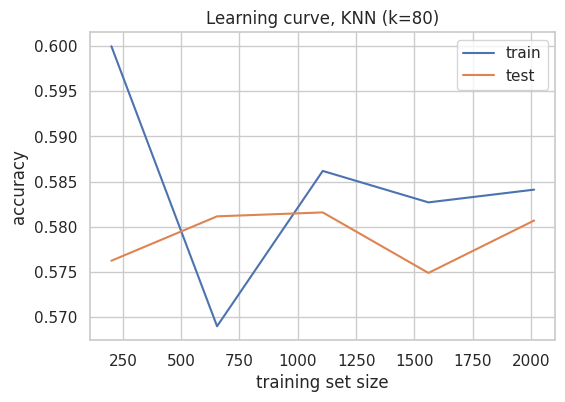

In [ ]:
train_sizes, train_scores, test_scores = learning_curve(
    KNeighborsClassifier(n_neighbors=80, p=1),
    X_train,
    y_train,
    cv=10,
    scoring='accuracy'
)

train_scores_mean = np.mean(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)

plt.plot(train_sizes, train_scores_mean, label='train')
plt.plot(train_sizes, test_scores_mean, label='test')
plt.xlabel('training set size')
plt.ylabel('accuracy')
plt.title('Learning curve, KNN (k=80)')
plt.legend();

In this learning curve, we can see that the training and test accuracy are very close together, which implies that the model is not overfitting and has low variance. Unfortunately, both accuracy values are pretty low and close to the baseline accuracy. This implies a high bias situation where the features are not strong enough to identify patterns in the data. Feature selection might be helpful here to identify better predictors.

### Feature Selection

Here we're going to use mutual information to see which of the predictors give us the most information about the injury severity.

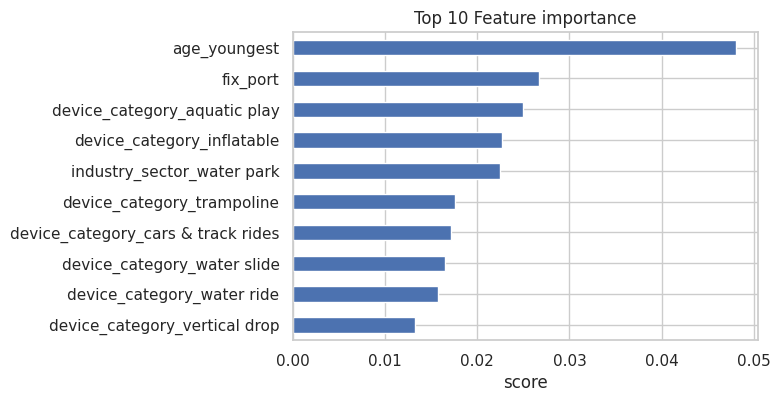

In [ ]:
selector = SelectKBest(mutual_info_classif, k=5)
selector.fit(X_train, y_train)

pd.Series(selector.scores_, index=predictors).sort_values().tail(10).plot.barh()
plt.title('Top 10 Feature importance')
plt.xlabel('score');

The top features, such as age_youngest and industry_sector_water park, have higher scores so they are useful for prediction.

In [ ]:
X_train_best = selector.transform(X_train)
X_test_best = selector.transform(X_test)

### KNN test score

In [ ]:
knn = knnCV.best_estimator_
knn.fit(X_train_best, y_train)

print(f'Test Score (selected features): {knn.score(X_test_best, y_test):.3f}')

Test Score (selected features): 0.552


Even after applying feature selection and using the best hyperparameters from GridSearchCV, the KNN model achieved a test accuracy of 0.559 which is slightly lower than the baseline accuracy of 0.576. We are seeing a high bias situation since the selected features are not useful enough for strong prediction.

### Decision Trees

In [ ]:
clf = DecisionTreeClassifier(max_depth=4, random_state=0)
cv_accuracy = cross_val_score(clf, X_train, y_train, cv=10).mean()
print(f'Cross Val accuracy: {cv_accuracy:.3f}')

Cross Val accuracy: 0.581


We can see that with the initial model with a max depth of 4, the accuracy is at 0.577, which is a .007 improvement over the baseline accuracy of .570

We will tune the model with GridSearchCV to obtain the best max depth and parameters.

In [ ]:
grid = {'max_depth': [1,3,9,20,50,80]}
treeCV = GridSearchCV(DecisionTreeClassifier( random_state=0), grid, cv=10)
treeCV.fit(X_train, y_train)
print(f'Best CV accuracy: {treeCV.best_score_:.3f}')
print(f"Best max depth: {treeCV.best_params_}")

Best CV accuracy: 0.584
Best max depth: {'max_depth': 3}


After tuning the tree model using GridSearchCV, we can see that the best max depth is 3 with an accuracy of .582. We can now train the model with the best max depth

In [ ]:
clf = DecisionTreeClassifier(max_depth=3, random_state=0)
clf.fit(X_train, y_train)
print(f'Test Score: {clf.score(X_test, y_test):.3f}')

Test Score: 0.567


The Decision Tree had a final test accuracy of 0.567, which is slightly below the baseline accuracy of 0.576, and a slight improvement over the KNN model test accuracy of 0.559

## Conclusions

During our exploration, we decided to predict the severity of an injury that can be caused by amusement park rides using the 2017 Safeparks dataset. We dropped various columns and chose predictors that could be obtained before a person gets on a ride. We set this up as a classification problem and trained and tested two models: KNN and decision trees. Both models ended up performing very close to the baseline accuracy of 0.576. The KNN model achieved a test accuracy of about 0.568 after applying feature selection and tuning, while the decision tree achieved about 0.567. These results only show very small differences from the baseline, meaning that factors such as ride category, type of park, and rider age are not strong predictors. Even after tuning the models and selecting the most important features, the predictors were not very informative and caused the models to struggle at finding strong patterns. Overall, there were minimal patterns captured by the model, and this could be due to the lack of context behind the data or simply that injury severity is caused by other factors not in this data set. This shows that having the right features matters just as much as the model you pick.